In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

In [7]:
data = pd.read_csv(
    "../data/processed/creditguard_engineered.csv"
)

print("Dataset shape:", data.shape)

Dataset shape: (500, 28)


In [8]:
selected_features = [
    "Income",
    "Credit_Score",
    "Credit_Utilization",
    "Missed_Payments",
    "Loan_Balance",
    "Debt_to_Income_Ratio",
    "Account_Tenure",
    "On_Time_Count",
    "Late_Count",
    "Missed_Count",
    "Payment_Issue_Count",
    "Payment_Issue_Rate",
    "Missed_Payment_Rate",
    "On_Time_Rate",
    "Average_Payment_Status"
]

X = data[selected_features].copy()
y = data["Delinquent_Account"].copy()

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (400, 15)
Testing: (100, 15)


In [10]:
logistic_model = joblib.load(
    "../models/logistic_regression.pkl"
)

random_forest_model = joblib.load(
    "../models/random_forest.pkl"
)

print("Models loaded successfully!")

Models loaded successfully!


In [11]:
logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = (
    logistic_model.predict_proba(X_test)[:,1]
    )
rf_predictions=random_forest_model.predict(X_test)
rf_probabilities = (
    random_forest_model.predict_proba(X_test)[:,1]
)

In [13]:
print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=["Non-delinquent","Delinquent"],
        zero_division=0
    )
)

                precision    recall  f1-score   support

Non-delinquent       0.80      0.49      0.61        84
    Delinquent       0.12      0.38      0.18        16

      accuracy                           0.47       100
     macro avg       0.46      0.43      0.40       100
  weighted avg       0.69      0.47      0.54       100



In [14]:
evaluation_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": (logistic_predictions == y_test).mean(),
        "Precision": precision_score(y_test, logistic_predictions, zero_division=0),
        "Recall": recall_score(y_test, logistic_predictions, zero_division=0),
        "F1": f1_score(y_test, logistic_predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, logistic_probabilities),
        "PR_AUC": average_precision_score(y_test, logistic_probabilities),
        "Brier_Score": brier_score_loss(y_test, logistic_probabilities)
    },
    {
        "Model": "Random Forest",
        "Accuracy": (rf_predictions == y_test).mean(),
        "Precision": precision_score(y_test, rf_predictions, zero_division=0),
        "Recall": recall_score(y_test, rf_predictions, zero_division=0),
        "F1": f1_score(y_test, rf_predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, rf_probabilities),
        "PR_AUC": average_precision_score(y_test, rf_probabilities),
        "Brier_Score": brier_score_loss(y_test, rf_probabilities)
    }
])

evaluation_results.set_index("Model").round(3)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Brier_Score
Model,,,,,,,
Logistic Regression,0.47,0.122,0.375,0.185,0.411,0.200,0.264
Random Forest,0.65,0.148,0.250,0.186,0.417,0.142,0.230


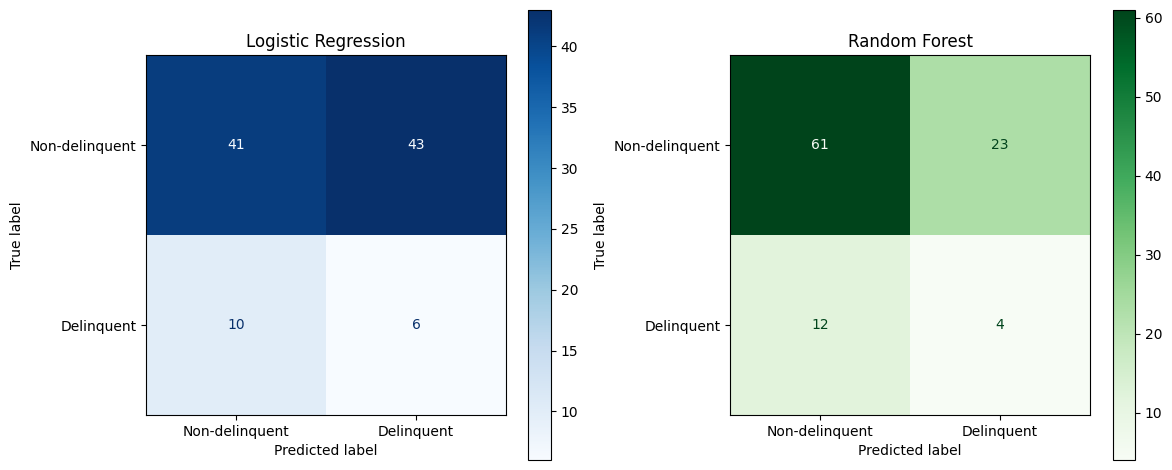

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["Non-delinquent", "Delinquent"],
    ax=axes[0],
    cmap="Blues"
)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["Non-delinquent", "Delinquent"],
    ax=axes[1],
    cmap="Greens"
)

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

In [16]:
coefficients = (
    logistic_model.named_steps["classifier"].coef_[0]
)

logistic_importance = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

logistic_importance = logistic_importance.sort_values(
    "Absolute_Importance",
    ascending=False
)

logistic_importance

,Feature,Coefficient,Absolute_Importance
0,Income,0.196582,0.196582
3,Missed_Payments,-0.156961,0.156961
6,Account_Tenure,-0.144666,0.144666
2,Credit_Utilization,0.135474,0.135474
5,Debt_to_Income_Ratio,0.107495,0.107495
1,Credit_Score,0.081899,0.081899
4,Loan_Balance,-0.057276,0.057276
9,Missed_Count,-0.025523,0.025523
12,Missed_Payment_Rate,-0.025523,0.025523
14,Average_Payment_Status,-0.023565,0.023565


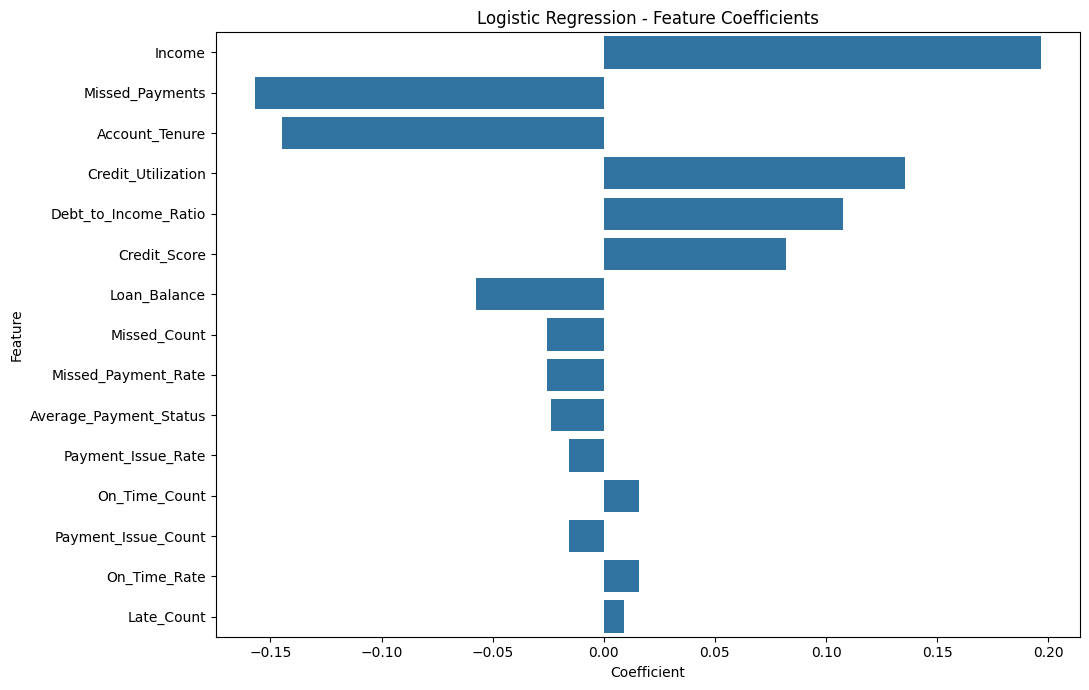

In [19]:
plt.figure(figsize=(11,7))
sns.barplot(
    data=logistic_importance,
    x="Coefficient",
    y="Feature"
)

plt.title("Logistic Regression - Feature Coefficients")
plt.tight_layout()
plt.show()

In [21]:
rf_importance = pd.DataFrame({
    "Feature":selected_features,
    "Importance":(
        random_forest_model
        .named_steps["classifier"]
        .feature_importances_
    )
})
rf_importance = rf_importance.sort_values(
    "Importance",
    ascending=False
)
rf_importance 

,Feature,Importance
2,Credit_Utilization,0.147246
5,Debt_to_Income_Ratio,0.120885
0,Income,0.109040
1,Credit_Score,0.108596
6,Account_Tenure,0.100679
4,Loan_Balance,0.098606
14,Average_Payment_Status,0.080805
3,Missed_Payments,0.058953
8,Late_Count,0.032150
7,On_Time_Count,0.027570


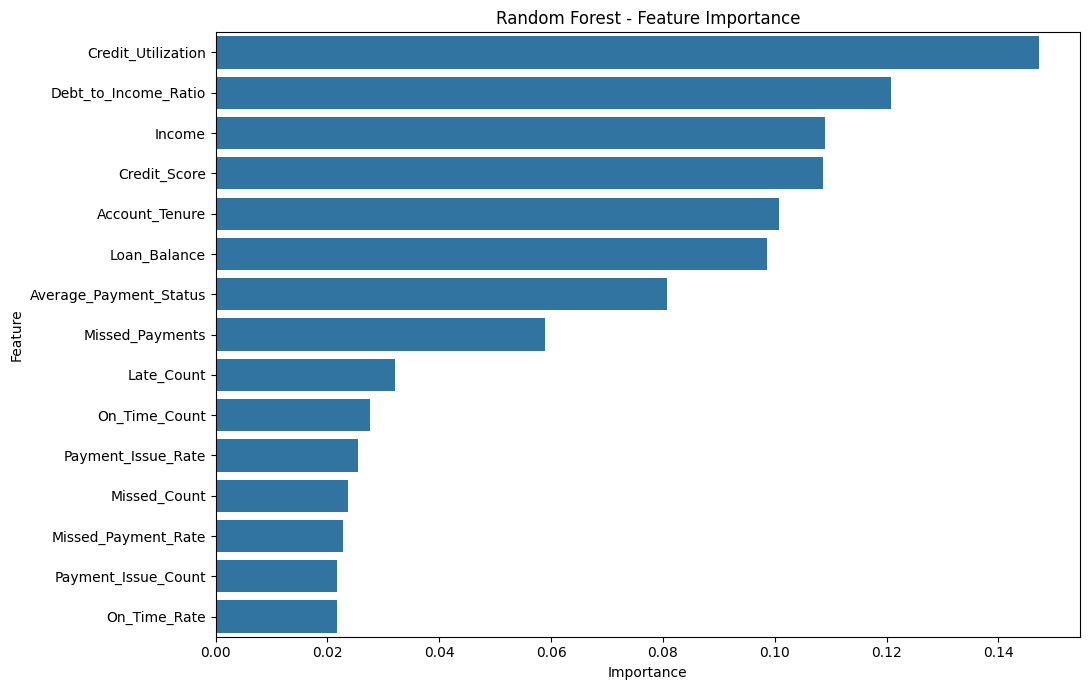

In [22]:
plt.figure(figsize=(11,7))
sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.tight_layout()
plt.show()

In [23]:
permutation_result = permutation_importance(
    logistic_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=20,
    random_state=42
)

permutation_df = pd.DataFrame({
    "Feature": selected_features,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
})

permutation_df = permutation_df.sort_values(
    "Importance_Mean",
    ascending=False
)

permutation_df

,Feature,Importance_Mean,Importance_Std
6,Account_Tenure,0.043218,0.013986
2,Credit_Utilization,0.040079,0.018252
0,Income,0.028318,0.027119
4,Loan_Balance,0.024935,0.013784
9,Missed_Count,0.009617,0.014544
12,Missed_Payment_Rate,0.009617,0.014544
14,Average_Payment_Status,0.006639,0.013712
3,Missed_Payments,0.005745,0.018808
8,Late_Count,0.002893,0.009170
10,Payment_Issue_Count,0.002784,0.009273


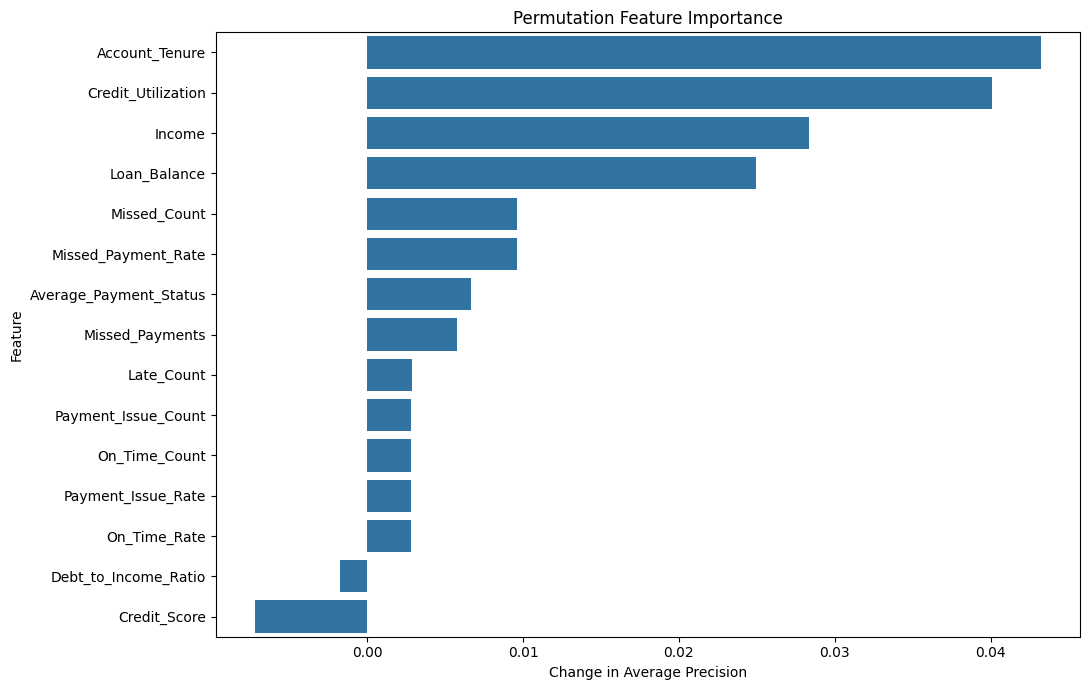

In [24]:
plt.figure(figsize=(11, 7))
sns.barplot(
    data=permutation_df,
    x="Importance_Mean",
    y="Feature"
)
plt.title("Permutation Feature Importance")
plt.xlabel("Change in Average Precision")
plt.tight_layout()
plt.show()

In [25]:
print(
    "Logistic Regression Brier Score:",
    round(brier_score_loss(y_test, logistic_probabilities), 4)
)

print(
    "Random Forest Brier Score:",
    round(brier_score_loss(y_test, rf_probabilities), 4)
)

Logistic Regression Brier Score: 0.264
Random Forest Brier Score: 0.2303


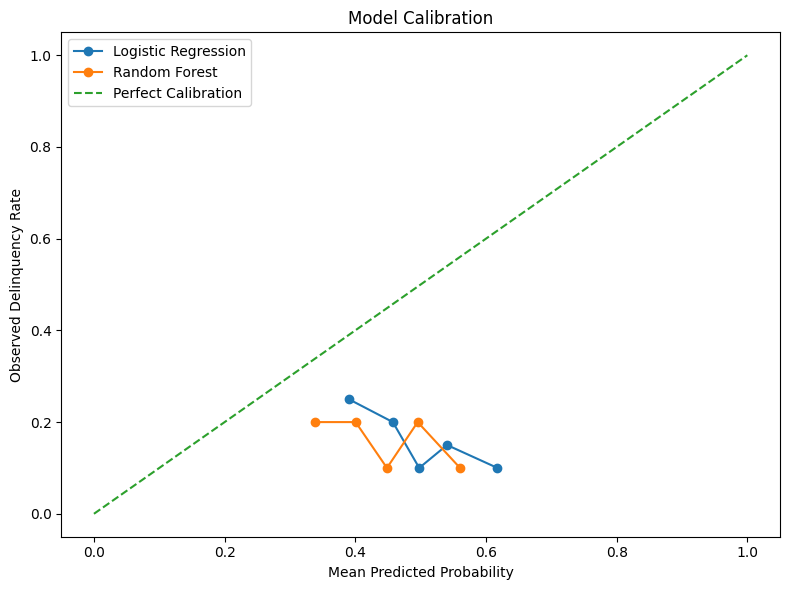

In [26]:
plt.figure(figsize=(8, 6))

for probabilities, name in [
    (logistic_probabilities, "Logistic Regression"),
    (rf_probabilities, "Random Forest")
]:

    fraction_positive, mean_predicted = calibration_curve(
        y_test,
        probabilities,
        n_bins=5,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=name
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect Calibration")

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Delinquency Rate")
plt.title("Model Calibration")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]
threshold_results = []

for threshold in thresholds:

    predictions = (
        logistic_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)

,Threshold,Precision,Recall,F1
0,0.3,0.160,1.000,0.276
1,0.4,0.146,0.812,0.248
2,0.5,0.122,0.375,0.185
3,0.6,0.167,0.125,0.143
4,0.7,1.000,0.062,0.118


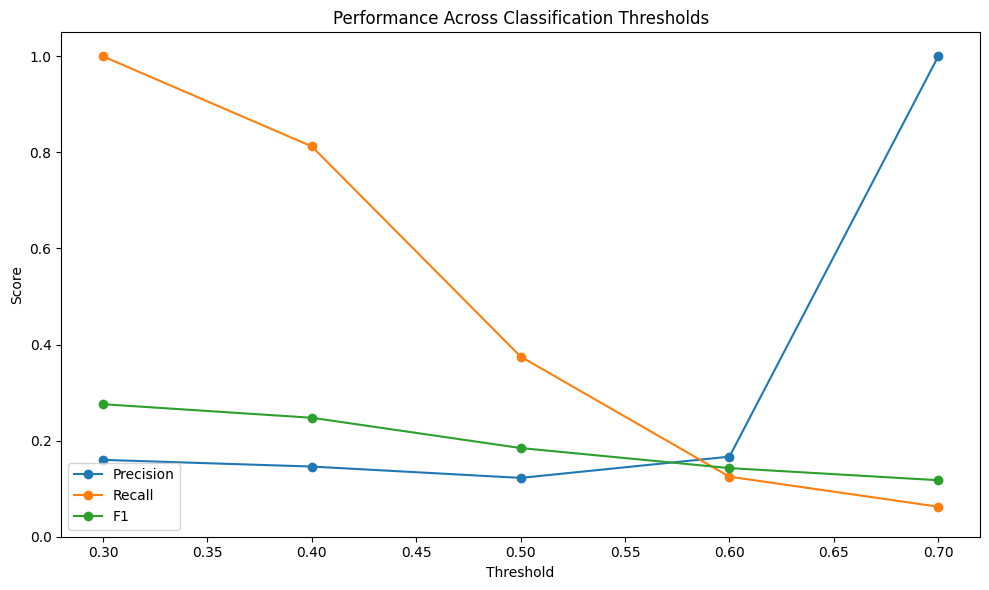

In [28]:
threshold_df.set_index("Threshold")[
    ["Precision", "Recall", "F1"]
].plot(
    marker="o",
    figsize=(10, 6)
)

plt.title("Performance Across Classification Thresholds")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [29]:
audit_data = data.loc[X_test.index].copy()
audit_data["Actual"] = y_test
audit_data["Predicted"] = logistic_predictions
audit_data["Probability"] = logistic_probabilities
print(audit_data.shape)

(100, 31)


In [30]:
audit_data["Age_Group"] = pd.cut(
    audit_data["Age"],
    bins=[0, 30, 45, 60, 120],
    labels=["18-30", "31-45", "46-60", "60+"]
)
audit_data["Age_Group"].value_counts(dropna=False)

Age_Group
31-45    29
60+      29
18-30    24
46-60    18
Name: count, dtype: int64

In [31]:
def group_metrics(group):

    return pd.Series({
        "Customers": len(group),
        "Actual_Delinquent": (group["Actual"] == 1).sum(),
        "Predicted_Delinquent": (group["Predicted"] == 1).sum(),
        "Recall": recall_score(
            group["Actual"],
            group["Predicted"],
            zero_division=0
        ),
        "Precision": precision_score(
            group["Actual"],
            group["Predicted"],
            zero_division=0
        )
    })


for column in ["Age_Group", "Location", "Employment_Status"]:
    print(f"\nFairness audit: {column}")
    print(
        audit_data.groupby(
            column,
            observed=False
        ).apply(group_metrics, include_groups=False)
    )


Fairness audit: Age_Group
           Customers  Actual_Delinquent  Predicted_Delinquent    Recall  \
Age_Group                                                                 
18-30           24.0                5.0                  11.0  0.400000   
31-45           29.0                4.0                  13.0  0.250000   
46-60           18.0                1.0                  10.0  1.000000   
60+             29.0                6.0                  15.0  0.333333   

           Precision  
Age_Group             
18-30       0.181818  
31-45       0.076923  
46-60       0.100000  
60+         0.133333  

Fairness audit: Location
             Customers  Actual_Delinquent  Predicted_Delinquent  Recall  \
Location                                                                  
Chicago           20.0                2.0                   8.0    0.00   
Houston           14.0                2.0                   8.0    0.50   
Los Angeles       26.0                6.0                 

In [32]:
os.makedirs("../reports", exist_ok=True)

In [33]:
evaluation_results.to_csv(
    "../reports/model_evaluation.csv",
    index=False
)

print("Evaluation results saved!")

Evaluation results saved!


In [34]:
permutation_df.to_csv(
    "../reports/permutation_importance.csv",
    index=False
)

logistic_importance.to_csv(
    "../reports/logistic_coefficients.csv",
    index=False
)

rf_importance.to_csv(
    "../reports/random_forest_importance.csv",
    index=False
)

print("Feature importance results saved!")

Feature importance results saved!


In [35]:
threshold_df.to_csv(
    "../reports/threshold_analysis.csv",
    index=False
)
print("Threshold analysis saved!")

Threshold analysis saved!
